In [1]:
import sys
from pathlib import Path

REPO = Path("/home/lingyu/ssd2/Python/Hist2Pheno")
if not (REPO / "code").is_dir():
    REPO = Path("/nobackup2/users/lingyu/Python/Hist2Pheno")
sys.path.insert(0, str(REPO / "code"))

from Hist2Pheno_pkg.external_validation import simple_cohort

_cohort = simple_cohort("HCC_NATURE", repo=REPO)
PRED_ROOT = _cohort.pred_root
composition_table = _cohort.composition_table
discover_samples = _cohort.discover_samples
geometry = _cohort.geometry
sample_paths = _cohort.sample_paths
ensure_l2_probs = _cohort.ensure_l2_probs
plot_spatial = _cohort.plot_spatial
plot_composition = _cohort.plot_composition
# Re-run the plot cell after changing these. Notebook display uses DPI; saved PNGs use SAVE_DPI.
SAVE_FIGURES = True
FIGSIZE = (17.2, 6.6)
DPI = 200
SAVE_DPI = 300
HE_MAX_SIDE = 1400
MARKER_PX = 1.0

READY_SAMPLES = (
    "L-8001_HE",
    "L-8002_HE",
    "L-8003_HE",
    "L-8004_HE",
    "L-8005_HE",
)
samples = discover_samples(list(READY_SAMPLES))
if samples != list(READY_SAMPLES):
    raise RuntimeError(
        f"Expected the five ready slides {list(READY_SAMPLES)}, got {samples}"
    )

for sample in samples:
    g = geometry(sample)
    print(
        f"{sample}  mpp={g['mpp_um']:.4f} µm/px ({g.get('mpp_source', '')})  "
        f"native16={g['patch_um_if_native_16px']:.2f} µm  "
        f"after rescale={g['patch_um_after_rescale']:.1f} µm  "
        f"scale={g['scale']:.4f}"
    )
    p = sample_paths(sample)
    print(f"  pred exists: {p['pred'].is_file()}  {p['pred']}")

L-8001_HE  mpp=1.0058 µm/px (Aperio MPP)  native16=16.09 µm  after rescale=8.0 µm  scale=2.0116
  pred exists: True  /home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/HCC/nature_data/pred_pancancer_section/L-8001_HE/L-8001_HE_stardist_pred.h5ad
L-8002_HE  mpp=0.5000 µm/px (cohort mpp_um fallback)  native16=8.00 µm  after rescale=8.0 µm  scale=1.0000
  pred exists: True  /home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/HCC/nature_data/pred_pancancer_section/L-8002_HE/L-8002_HE_stardist_pred.h5ad
L-8003_HE  mpp=0.5000 µm/px (cohort mpp_um fallback)  native16=8.00 µm  after rescale=8.0 µm  scale=1.0000
  pred exists: True  /home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/HCC/nature_data/pred_pancancer_section/L-8003_HE/L-8003_HE_stardist_pred.h5ad
L-8004_HE  mpp=0.5000 µm/px (cohort mpp_um fallback)  native16=8.00 µm  after rescale=8.0 µm  scale=1.0000
  pred exists: True  /home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/HCC/nature_data/pred_pancancer_section/L-8004_HE/L-8004_HE_stardist_pred.

In [2]:
import pandas as pd
from IPython.display import display

missing = [s for s in samples if not sample_paths(s)["pred"].is_file()]
if missing:
    raise FileNotFoundError(
        "No predictions yet for "
        + ", ".join(missing)
        + ". Run: CUDA_DEVICE=1 bash code/External_val/HCC_nature/predict_ready.sh"
    )

comp = composition_table(samples)

for head in ("L1", "L12", "L2"):
    sub = comp.loc[comp["head"] == head].copy()
    order = sub.groupby("class")["fraction"].max().sort_values(ascending=False).index
    wide = (
        sub.pivot_table(index="class", columns="sample", values=["fraction", "n", "mean_conf"])
        .reindex(order)
    )
    print(f"\n===== {head} =====")
    display(wide.round(3))


===== L1 =====


fraction                                         mean_conf  \
sample      L-8001_HE L-8002_HE L-8003_HE L-8004_HE L-8005_HE L-8001_HE   
class                                                                     
Epithelial      0.000     0.081     0.642     0.171     0.276     0.393   
Endothelial     0.397     0.597     0.079     0.367     0.542     0.405   
Immune          0.317     0.320     0.279     0.435     0.180     0.406   
Stromal         0.285     0.001     0.000     0.026     0.002     0.411   
Neural            NaN     0.001       NaN     0.001     0.000       NaN   

                                                            n            \
sample      L-8002_HE L-8003_HE L-8004_HE L-8005_HE L-8001_HE L-8002_HE   
class                                                                     
Epithelial      0.422     0.536     0.418     0.437       3.0   12763.0   
Endothelial     0.471     0.438     0.415     0.427   31033.0   94288.0   
Immune          0.426     0.473     0.407     0.402   24804.0   50627.0   
Stromal         0.348     0.400     0.384     0.370   22294.0     218.0   
Neural          0.340       NaN     0.350     0.258       NaN     158.0   

                                           
sample      L-8003_HE L-8004_HE L-8005_HE  
class                                      
Epithelial   238993.0   15846.0   30741.0  
Endothelial   29317.0   34043.0   60512.0  
Immune       103730.0   40342.0   20045.0  
Stromal          35.0    2402.0     253.0  
Neural            NaN      90.0       1.0


===== L12 =====


fraction                                         mean_conf  \
sample      L-8001_HE L-8002_HE L-8003_HE L-8004_HE L-8005_HE L-8001_HE   
class                                                                     
Myeloid         0.316     0.974     0.230     0.973     0.874     0.303   
T_cell          0.462     0.002     0.551     0.007     0.002     0.326   
Stromal         0.218     0.003     0.000     0.008     0.009     0.317   
Epithelial        NaN     0.007     0.172     0.006     0.099       NaN   
Tumor             NaN     0.000     0.043     0.002     0.000       NaN   
Endothelial     0.002     0.014     0.004     0.003     0.015     0.270   
B_Plasma        0.003     0.000     0.000     0.002     0.000     0.271   

                                                            n            \
sample      L-8002_HE L-8003_HE L-8004_HE L-8005_HE L-8001_HE L-8002_HE   
class                                                                     
Myeloid         0.539     0.363     0.557     0.466   24726.0  153882.0   
T_cell          0.342     0.421     0.338     0.336   36062.0     310.0   
Stromal         0.311     0.322     0.352     0.320   17002.0     405.0   
Epithelial      0.405     0.416     0.381     0.405       NaN    1132.0   
Tumor           0.452     0.380     0.427     0.352       NaN      58.0   
Endothelial     0.359     0.312     0.326     0.331     137.0    2191.0   
B_Plasma        0.362     0.339     0.392     0.324     207.0      76.0   

                                           
sample      L-8003_HE L-8004_HE L-8005_HE  
class                                      
Myeloid       85459.0   90179.0   97519.0  
T_cell       204921.0     660.0     221.0  
Stromal          79.0     753.0    1043.0  
Epithelial    63857.0     530.0   11065.0  
Tumor         16164.0     176.0      34.0  
Endothelial    1424.0     259.0    1629.0  
B_Plasma        171.0     166.0      41.0


===== L2 =====


fraction                                         mean_conf  \
sample            L-8001_HE L-8002_HE L-8003_HE L-8004_HE L-8005_HE L-8001_HE   
class                                                                           
Macrophage            0.026     0.606     0.102     0.731     0.564     0.164   
Fibroblast            0.412     0.000     0.000     0.022     0.003     0.219   
CD8_T                 0.006     0.000     0.356     0.001     0.001     0.175   
Epithelial              NaN     0.001     0.331     0.000     0.014       NaN   
Plasma                0.284     0.001     0.000     0.005     0.007     0.219   
Endothelial           0.126     0.176     0.056     0.050     0.148     0.177   
Injury_epithelial       NaN     0.018     0.007     0.022     0.094       NaN   
Alveolar                NaN     0.084     0.000     0.070     0.087       NaN   
Tumor                 0.000     0.005     0.082     0.022     0.002     0.223   
CD4_T                 0.078       NaN     0.001       NaN       NaN     0.183   
B_cell                0.067     0.004     0.048     0.010     0.002     0.187   
NK                    0.000     0.061     0.000     0.043     0.021     0.151   
Neutrophil            0.000     0.028     0.017     0.013     0.030     0.166   
Myofibroblast         0.000     0.016     0.000     0.010     0.028     0.184   
Stromal                 NaN     0.001       NaN     0.001     0.000       NaN   
Neural                  NaN     0.000       NaN     0.000       NaN       NaN   
Tregs                   NaN     0.000       NaN       NaN       NaN       NaN   
DC                      NaN       NaN     0.000       NaN       NaN       NaN   

                                                                  n            \
sample            L-8002_HE L-8003_HE L-8004_HE L-8005_HE L-8001_HE L-8002_HE   
class                                                                           
Macrophage            0.252     0.203     0.276     0.235    2024.0   95854.0   
Fibroblast            0.169     0.218     0.236     0.200   32227.0      39.0   
CD8_T                 0.173     0.271     0.189     0.198     481.0      41.0   
Epithelial            0.290     0.298     0.184     0.213       NaN     111.0   
Plasma                0.187     0.158     0.243     0.198   22208.0     123.0   
Endothelial           0.225     0.203     0.204     0.207    9808.0   27770.0   
Injury_epithelial     0.244     0.204     0.243     0.243       NaN    2901.0   
Alveolar              0.206     0.173     0.213     0.194       NaN   13251.0   
Tumor                 0.300     0.273     0.294     0.267       1.0     788.0   
CD4_T                   NaN     0.163       NaN       NaN    6116.0       NaN   
B_cell                0.268     0.233     0.368     0.493    5233.0     636.0   
NK                    0.209     0.182     0.218     0.196       3.0    9574.0   
Neutrophil            0.253     0.214     0.233     0.250      25.0    4395.0   
Myofibroblast         0.209     0.186     0.193     0.189       8.0    2452.0   
Stromal               0.177       NaN     0.185     0.212       NaN     108.0   
Neural                0.148       NaN     0.191       NaN       NaN       2.0   
Tregs                 0.164       NaN       NaN       NaN       NaN       9.0   
DC                      NaN     0.179       NaN       NaN       NaN       NaN   

                                                 
sample            L-8003_HE L-8004_HE L-8005_HE  
class                                            
Macrophage          37913.0   67799.0   62867.0  
Fibroblast             39.0    2036.0     282.0  
CD8_T              132497.0      77.0      66.0  
Epithelial         123092.0      18.0    1561.0  
Plasma                 99.0     478.0     733.0  
Endothelial         20761.0    4643.0   16541.0  
Injury_epithelial    2510.0    2022.0   10537.0  
Alveolar               26.0    6448.0    9657.0  
Tumor               30655.0    2058.0     252.0  
CD4_T          

[plot] L-8001_HE  nuclei=78,134  neighbor=12.8px  figsize=(17.2, 12.54)  dpi=200  marker_px=1.0  rows=HE+points
[plot] /home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/HCC/nature_data/pred_pancancer_section/figures/L-8001_HE_spatial_L1_L12_L2.png  save_dpi=300
[plot] L-8002_HE  nuclei=158,054  neighbor=10.6px  figsize=(17.2, 12.54)  dpi=200  marker_px=1.0  rows=HE+points
[plot] /home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/HCC/nature_data/pred_pancancer_section/figures/L-8002_HE_spatial_L1_L12_L2.png  save_dpi=300
[plot] L-8003_HE  nuclei=372,075  neighbor=10.0px  figsize=(17.2, 12.54)  dpi=200  marker_px=1.0  rows=HE+points
[plot] /home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/HCC/nature_data/pred_pancancer_section/figures/L-8003_HE_spatial_L1_L12_L2.png  save_dpi=300
[plot] L-8004_HE  nuclei=92,723  neighbor=13.8px  figsize=(17.2, 12.54)  dpi=200  marker_px=1.0  rows=HE+points
[plot] /home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/HCC/nature_data/pred_pancancer_section/figures/L-80

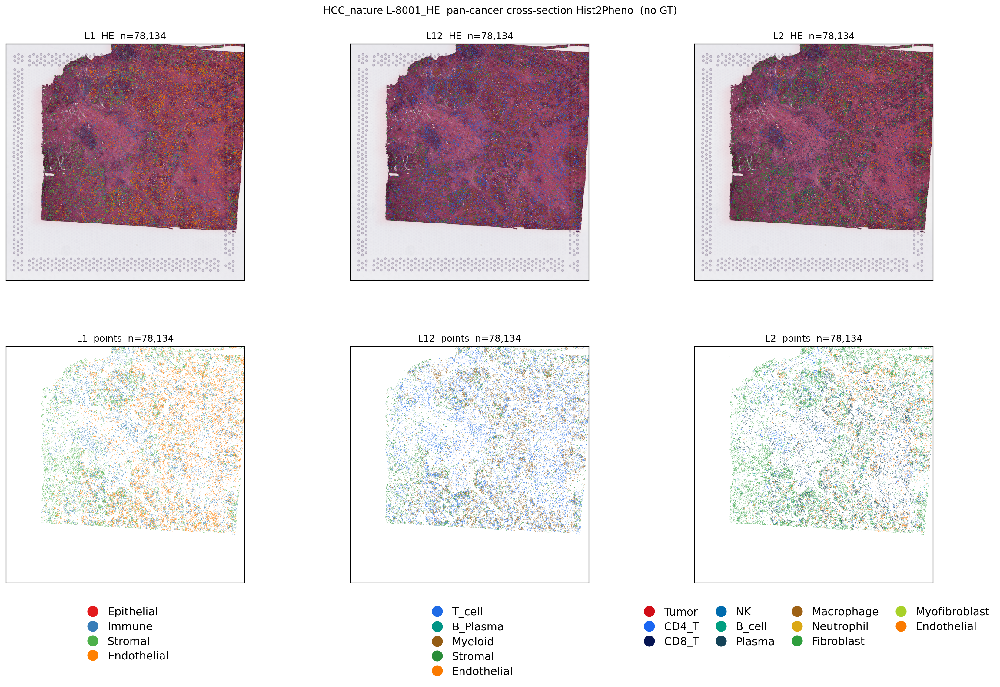

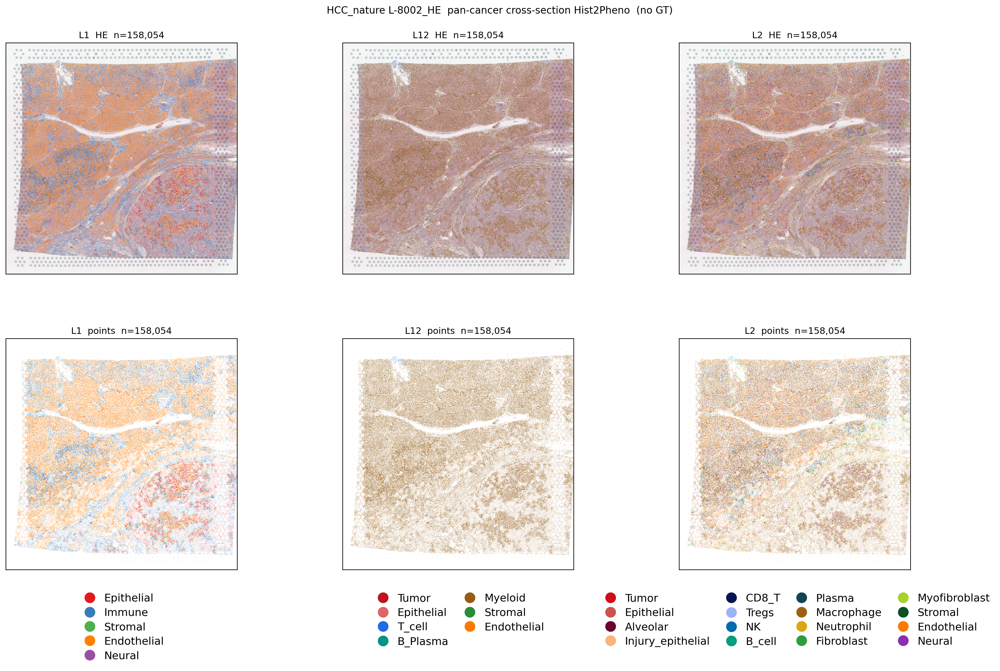

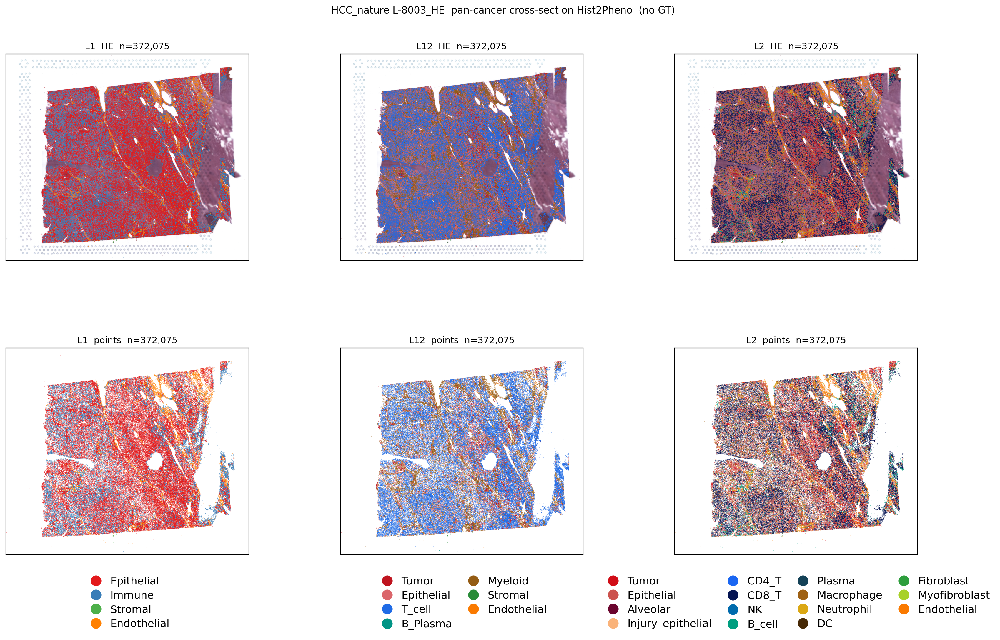

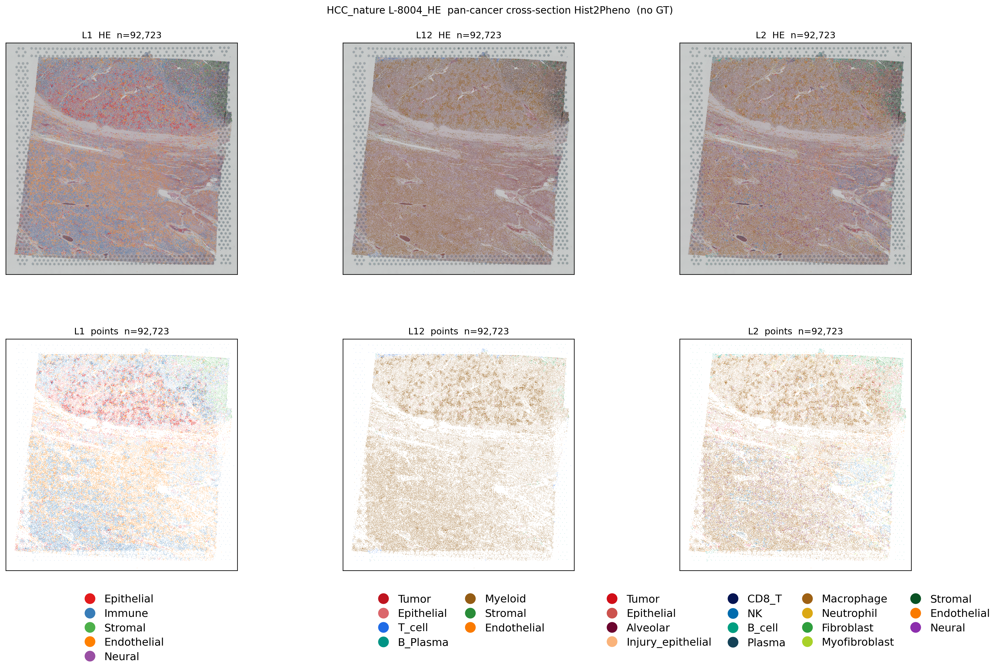

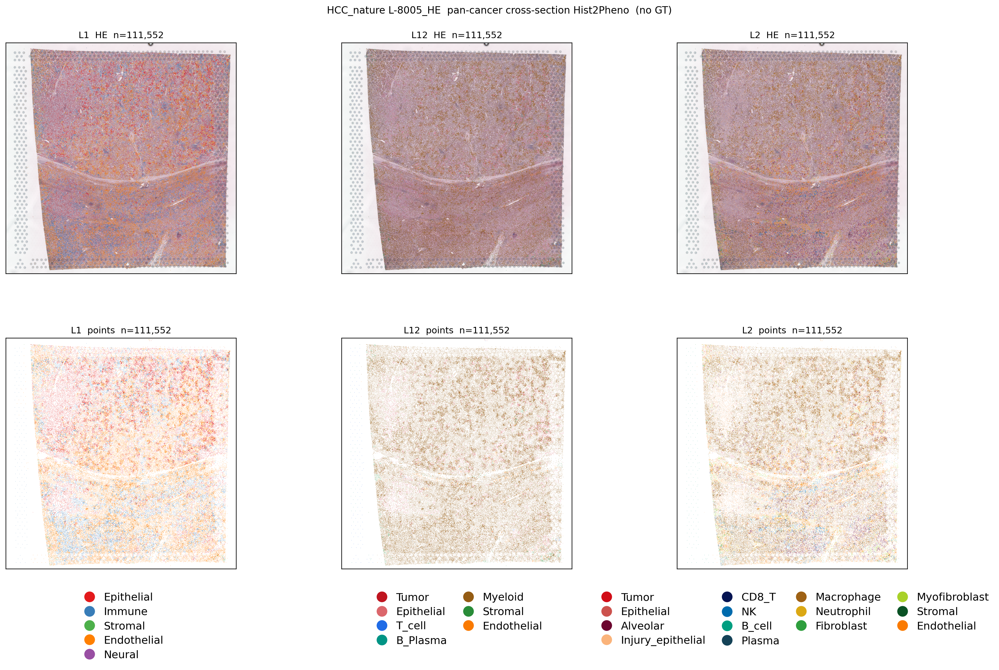

In [3]:
import matplotlib.pyplot as plt

for fig in plot_spatial(
    samples,
    figsize=FIGSIZE,
    dpi=DPI,
    he_max_side=HE_MAX_SIDE,
    marker_px=MARKER_PX,
    save=SAVE_FIGURES,
    save_dpi=SAVE_DPI,
):
    display(fig)
    plt.close(fig)

[plot] /home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/HCC/nature_data/pred_pancancer_section/figures/composition_L1.png  save_dpi=300
[plot] /home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/HCC/nature_data/pred_pancancer_section/figures/composition_L12.png  save_dpi=300
[plot] /home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/HCC/nature_data/pred_pancancer_section/figures/composition_L2.png  save_dpi=300


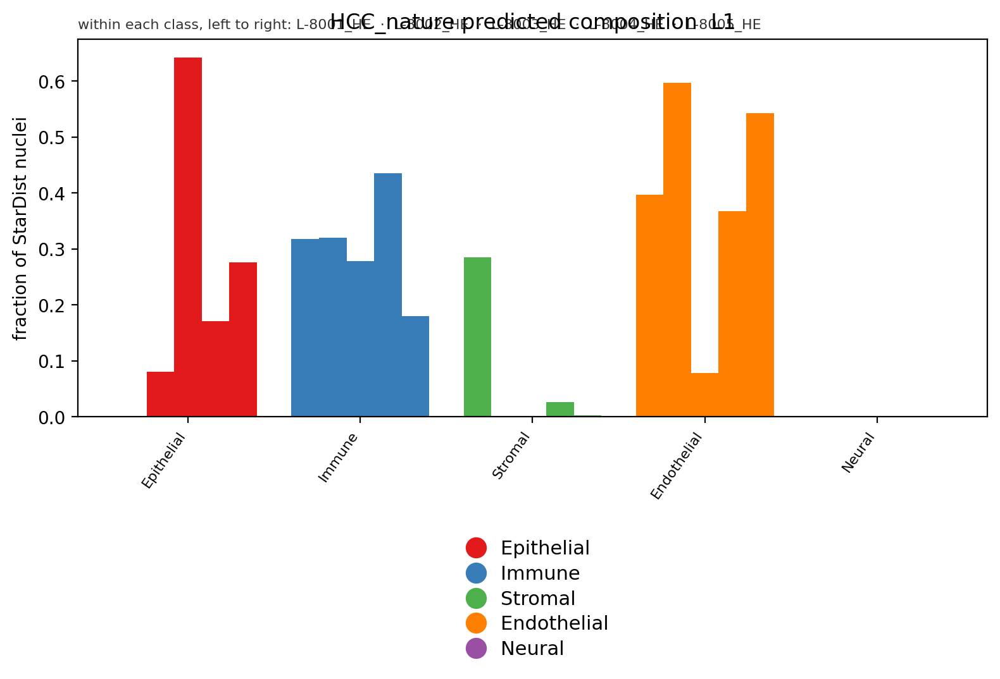

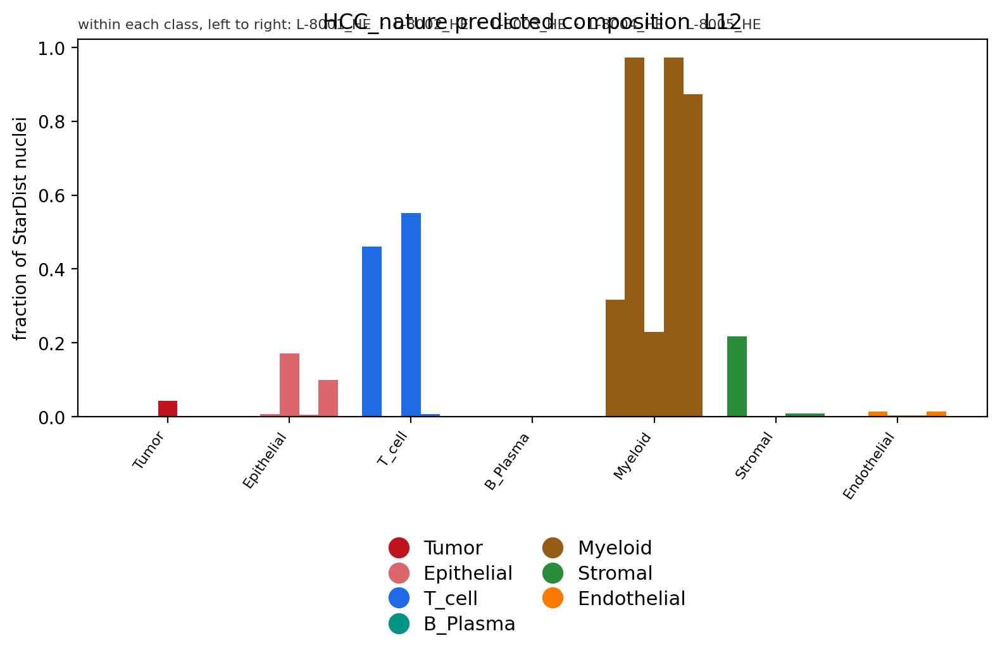

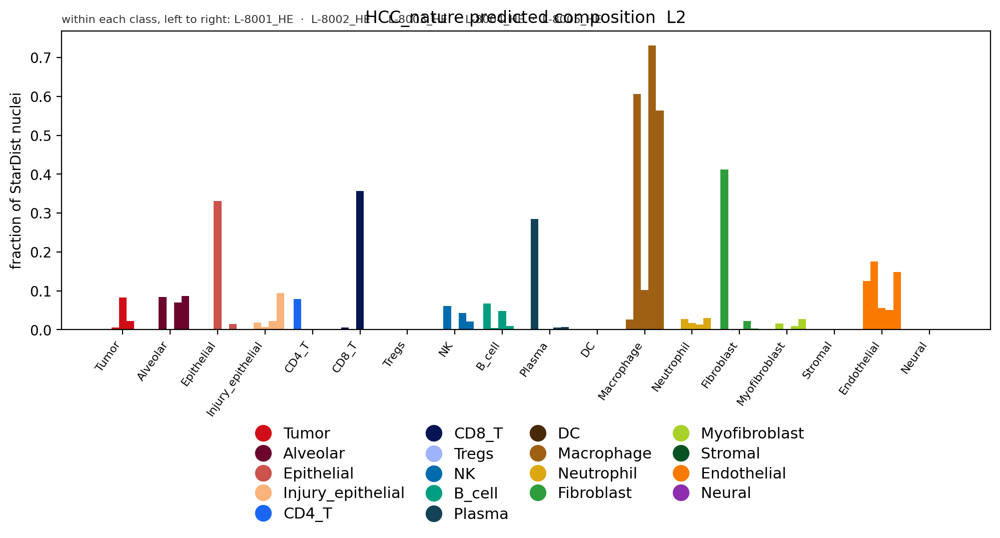

In [4]:
for fig in plot_composition(samples, save=SAVE_FIGURES, dpi=DPI, save_dpi=SAVE_DPI):
    display(fig)
    plt.close(fig)

## Histology-derived niche indices (TLS / SRI / TNI)

Same implementation as `code/Xenium_lung/histology_derived_niche_index.ipynb` §3, via `Hist2Pheno_pkg/histology_niche_index.py`. Lung ARI / FRI are not used.

Scores use **L2 softmax**, not the argmax label. `ensure_l2_probs` caches `{sample}_l2_probs.npz`.

| Index | Abundance | Spatial (radius R) |
|--|--|--|
| **TLS** | sum(B_cell + Plasma + CD4_T + CD8_T + Tregs + DC) | `(B_local × T_local × DC_local)^(1/3)` |
| **SRI** | (Fibroblast + Myofibroblast + Stromal) / epithelium | Fib_local / Epi_local |
| **TNI** | (fibroblast + Macrophage + Endothelial) / epithelium | `(Fib × Mac × Endo)^(1/3) / Epi_local` |

Epithelium = Epithelial, Tumor, Alveolar, Injury_epithelial, DCIS, Myoepithelial. NK is left out of TLS. `spatial_HE` is native TIFF pixels, so R = **55 µm** is converted with **that slide's** µm/px (OME / Aperio / fallback), not with a global 0.5 unless that is the value for the slide. TLS, SRI, and TNI each use a 1×3 row: abundance, spatial score without markers, then the same spatial map with cyan candidates.

In [5]:
import importlib

for _p in (REPO / "code" / "Hist2Pheno_pkg", REPO / "code" / "Xenium_lung"):
    if str(_p) not in sys.path:
        sys.path.insert(0, str(_p))

import histology_niche_index as hni
importlib.reload(hni)
import histology_derived_niche_index as hdni
importlib.reload(hdni)
from histology_niche_index import OrganNicheConfig

import anndata as ad

TLS_RADIUS_UM = 55.0
RECOMPUTE_NICHE = False

HCC_NATURE_NICHE = OrganNicheConfig(
    pan_organ="pancancer_hcc_nature_ready",
    tls_b=("B_cell", "Plasma"),
    tls_t=("CD4_T", "CD8_T", "Tregs"),
    tls_dc=("DC",),
    epithelium=(
        "Epithelial", "Tumor", "Alveolar",
        "Injury_epithelial", "DCIS", "Myoepithelial",
    ),
    fibroblast=("Fibroblast", "Myofibroblast", "Stromal"),
    endothelial=("Endothelial",),
    macrophage=("Macrophage",),
    um_per_he_pixel=float(geometry(samples[0])["mpp_um"]),
    spatial_radius_um=TLS_RADIUS_UM,
    cohort="HCC_nature_ready",
)
display(hni.index_formula_table(HCC_NATURE_NICHE))

,index,formula
0,TLS,sum(B_cell+ Plasma+ CD4_T+ CD8_T+ Tregs+ DC)
1,TLS_spatial,(B_local × T_local × DC_local)^(1/3) within ra...
2,SRI_ratio,Fibroblast+Myofibroblast+Stromal / Epithelial+...
3,SRI_spatial,Fib_local / Epi_local within radius R μm
4,TNI_ratio,(Fibroblast+Myofibroblast+Stromal + Macrophage...
5,TNI_spatial,(Fib_local × myeloid_local × Endo_local)^(1/3)...


In [6]:
import numpy as np
niche_frames = {}
for sample in samples:
    paths = sample_paths(sample)
    niche_path = paths["pred"].with_name(f"{sample}_niche_indices.h5ad")
    mpp = float(geometry(sample)["mpp_um"])
    if niche_path.is_file() and not RECOMPUTE_NICHE:
        cached = ad.read_h5ad(niche_path)
        df = cached.obs.copy()
        xy = np.asarray(cached.obsm["spatial_HE"], dtype=np.float64)
        df["coord_x"] = xy[:, 0]
        df["coord_y"] = xy[:, 1]
        print(f"[niche] cache {niche_path.name}  n={len(df):,}  µm/px={mpp:.4f}")
    else:
        probs, class_names = ensure_l2_probs(sample)
        missing = hni.missing_index_cell_types(class_names, HCC_NATURE_NICHE)
        if missing:
            raise RuntimeError(f"{sample} missing niche compartments: {missing}")
        pred = ad.read_h5ad(paths["pred"])
        coords = np.asarray(pred.obsm["spatial_HE"], dtype=np.float64)
        df = pred.obs.copy()
        df["coord_x"] = coords[:, 0]
        df["coord_y"] = coords[:, 1]
        df = hni.add_abundance_indices(df, probs, class_names, HCC_NATURE_NICHE)
        df = hni.add_spatial_indices(
            df, probs, class_names, coords, HCC_NATURE_NICHE,
            radius_um=TLS_RADIUS_UM,
            um_per_pixel=mpp,
        )
        out = ad.AnnData(obs=df.drop(columns=["coord_x", "coord_y"]))
        out.obsm["spatial_HE"] = coords
        out.uns["tls_radius_um"] = TLS_RADIUS_UM
        out.uns["um_per_px"] = mpp
        out.write_h5ad(niche_path)
        print(f"[niche] wrote {niche_path}  n={len(df):,}")
    niche_frames[sample] = df
    print(f"  TLS hotspot: {hni.summarize_tls_hotspots(df)}")
    print(
        f"  mean TLS={df['idx_TLS'].mean():.3f}  TLS_spatial={df['idx_TLS_spatial'].mean():.3f}  "
        f"SRI={df['idx_SRI_ratio'].mean():.3f}  TNI={df['idx_TNI_ratio'].mean():.3f}"
    )

[niche] cache L-8001_HE_niche_indices.h5ad  n=78,134  µm/px=1.0058
  TLS hotspot: {'n_cells_total': 78134, 'n_candidate_cells': 3907, 'fraction_candidate': 0.05000383955768296, 'max_tls_spatial': 0.19005132417532788, 'mean_tls_spatial_candidate': 0.1412728278041978, 'centroid_x': 3528.3956414274708, 'centroid_y': 2556.7313698875096}
  mean TLS=0.475  TLS_spatial=0.116  SRI=8.518  TNI=17.089
[niche] cache L-8002_HE_niche_indices.h5ad  n=158,054  µm/px=0.5000
  TLS hotspot: {'n_cells_total': 158054, 'n_candidate_cells': 7903, 'fraction_candidate': 0.050001898085464465, 'max_tls_spatial': 0.18821324936761605, 'mean_tls_spatial_candidate': 0.07945308771402496, 'centroid_x': 3957.802295241343, 'centroid_y': 4122.135755464387}
  mean TLS=0.127  TLS_spatial=0.037  SRI=0.666  TNI=2.687
[niche] cache L-8003_HE_niche_indices.h5ad  n=372,075  µm/px=0.5000
  TLS hotspot: {'n_cells_total': 372075, 'n_candidate_cells': 18604, 'fraction_candidate': 0.05000067190754552, 'max_tls_spatial': 0.1463819448

/home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/HCC/nature_data/pred_pancancer_section/figures_ready/tls_score_summary.csv


,sample,n,TLS_mean,TLS_median,TLS_p95,TLS_max,TLS_spatial_mean,TLS_spatial_median,TLS_spatial_p95,TLS_spatial_max,pearson,spearman,top5_jaccard,abundance_top5_also_spatial_top5,TLS_spatial_mean_in_abundance_top5,TLS_mean_in_spatial_top5
0,L-8001_HE,78134,0.475,0.470,0.596,0.861,0.116,0.116,0.132,0.190,0.348,0.288,0.161,0.278,0.126,0.553
1,L-8002_HE,158054,0.127,0.108,0.262,0.885,0.037,0.033,0.066,0.188,0.780,0.656,0.418,0.590,0.071,0.293
2,L-8003_HE,372075,0.402,0.395,0.630,0.905,0.086,0.085,0.106,0.146,0.439,0.416,0.119,0.213,0.096,0.525
3,L-8004_HE,92723,0.128,0.108,0.261,0.941,0.037,0.032,0.069,0.183,0.848,0.824,0.447,0.618,0.079,0.339
4,L-8005_HE,111552,0.137,0.125,0.240,0.848,0.038,0.037,0.053,0.172,0.727,0.624,0.255,0.406,0.054,0.248


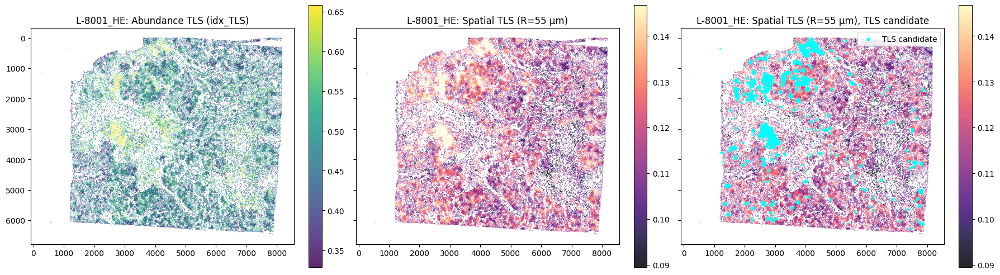

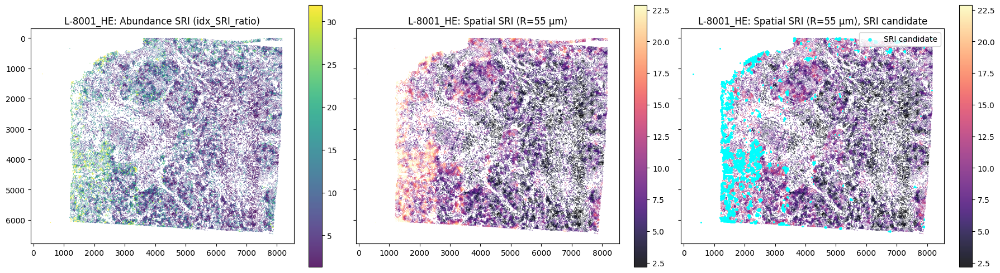

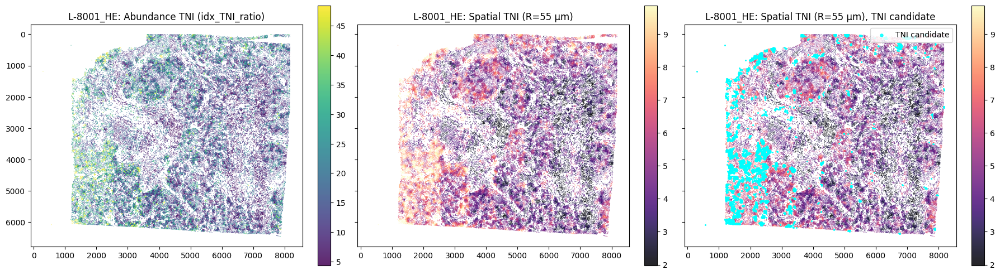

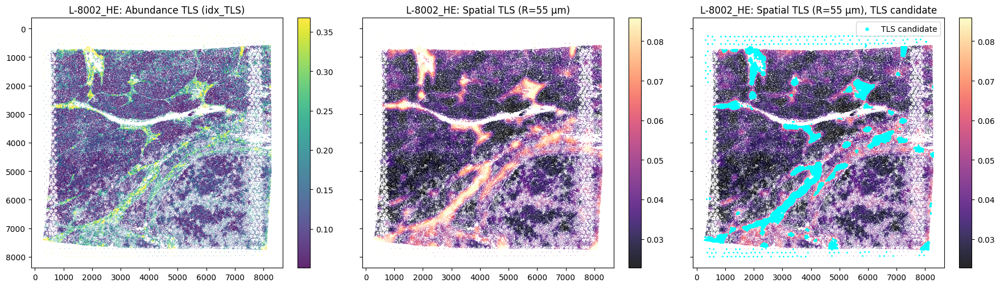

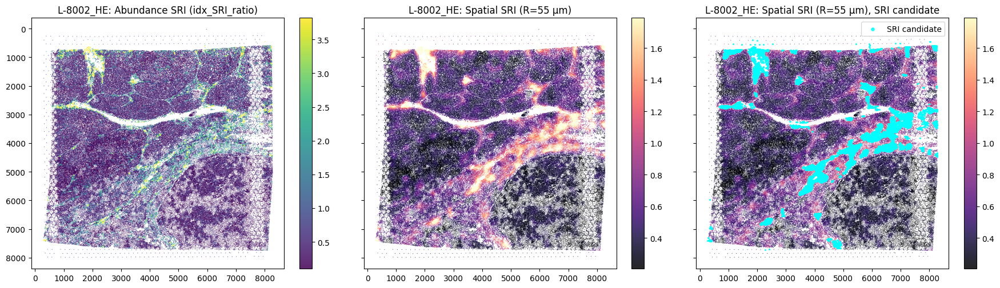

...

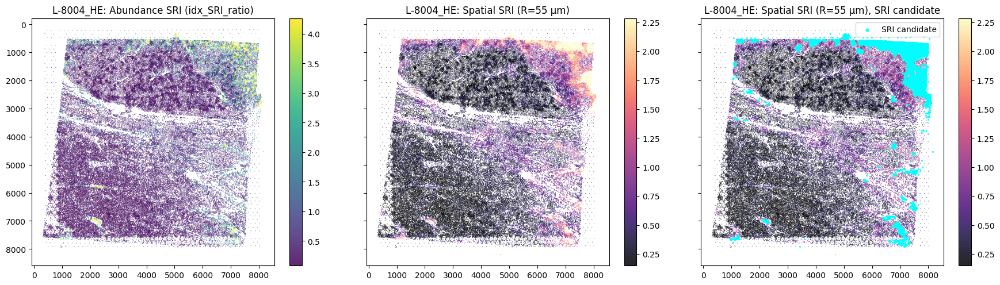

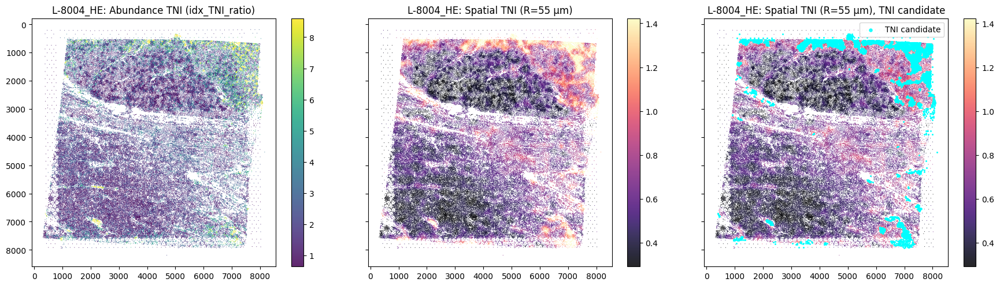

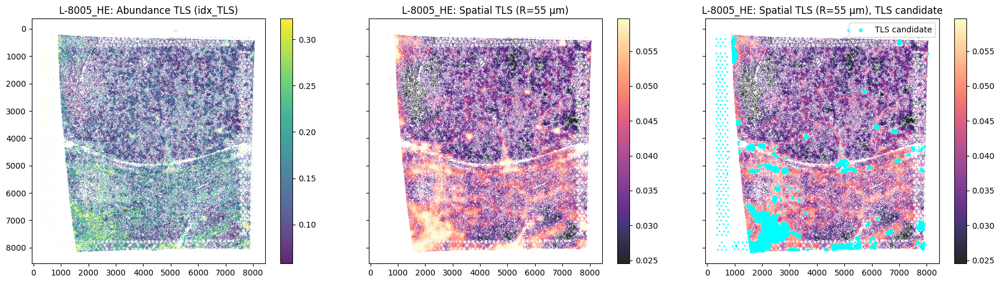

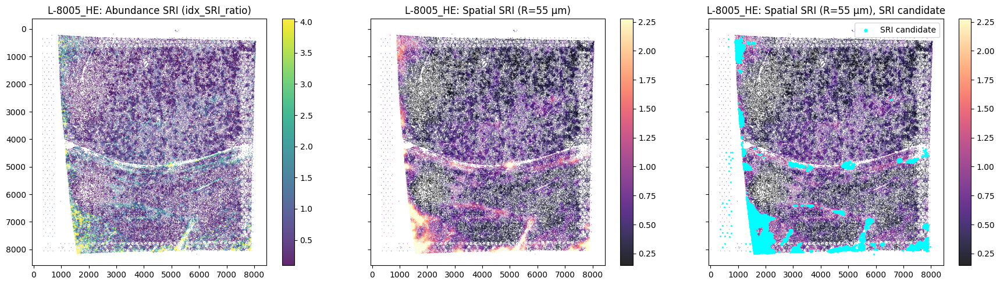

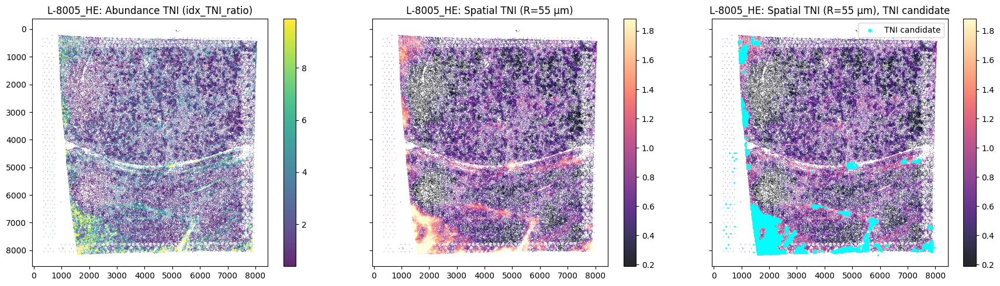

In [7]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

fig_dir = PRED_ROOT / "figures_ready"
fig_dir.mkdir(parents=True, exist_ok=True)


def tls_score_row(df, sample: str) -> dict:
    a = df["idx_TLS"].to_numpy(dtype=float)
    s = df["idx_TLS_spatial"].to_numpy(dtype=float)
    a_hi = a >= np.percentile(a, 95)
    s_hi = df["tls_candidate"].fillna(False).astype(bool).to_numpy()
    inter = int(np.logical_and(a_hi, s_hi).sum())
    union = int(np.logical_or(a_hi, s_hi).sum())
    n_a = int(a_hi.sum())
    return {
        "sample": sample,
        "n": int(len(df)),
        "TLS_mean": float(np.mean(a)),
        "TLS_median": float(np.median(a)),
        "TLS_p95": float(np.percentile(a, 95)),
        "TLS_max": float(np.max(a)),
        "TLS_spatial_mean": float(np.mean(s)),
        "TLS_spatial_median": float(np.median(s)),
        "TLS_spatial_p95": float(np.percentile(s, 95)),
        "TLS_spatial_max": float(np.max(s)),
        "pearson": float(np.corrcoef(a, s)[0, 1]),
        "spearman": float(pd.Series(a).corr(pd.Series(s), method="spearman")),
        "top5_jaccard": (inter / union) if union else float("nan"),
        "abundance_top5_also_spatial_top5": (inter / n_a) if n_a else float("nan"),
        "TLS_spatial_mean_in_abundance_top5": float(s[a_hi].mean()) if n_a else float("nan"),
        "TLS_mean_in_spatial_top5": float(a[s_hi].mean()) if s_hi.any() else float("nan"),
    }


quant_rows = [tls_score_row(df, sample) for sample, df in niche_frames.items()]
tls_quant = pd.DataFrame(quant_rows)
tls_quant_path = fig_dir / "tls_score_summary.csv"
tls_quant.to_csv(tls_quant_path, index=False)
print(tls_quant_path)
display(tls_quant.round(3))

for sample, df in niche_frames.items():
    fig, axes = hdni.plot_tls_abundance_vs_spatial(
        df,
        sample,
        radius_um=TLS_RADIUS_UM,
        use_entropy=False,
        split_spatial_candidates=True,
        dpi=DPI,
        save_dpi=SAVE_DPI,
        point_size=0.15,
        candidate_size=1.2,
        save_path=(fig_dir / f"{sample}_TLS_abundance_vs_spatial.png") if SAVE_FIGURES else None,
    )
    display(fig)
    plt.close(fig)

    for abundance_col, spatial_col, candidate_col, tag in (
        ("idx_SRI_ratio", "idx_SRI_spatial", "sri_candidate", "SRI"),
        ("idx_TNI_ratio", "idx_TNI_spatial", "tni_candidate", "TNI"),
    ):
        fig, axes = hdni.plot_tls_abundance_vs_spatial(
            df,
            sample,
            radius_um=TLS_RADIUS_UM,
            abundance_col=abundance_col,
            spatial_col=spatial_col,
            candidate_col=candidate_col,
            score_name=tag,
            use_entropy=False,
            split_spatial_candidates=True,
            dpi=DPI,
            save_dpi=SAVE_DPI,
            point_size=0.15,
            candidate_size=1.2,
            save_path=(fig_dir / f"{sample}_{tag}_abundance_vs_spatial.png") if SAVE_FIGURES else None,
        )
        display(fig)
        plt.close(fig)